### Train Classifier

In [2]:
import torch
import pandas as pd
import numpy as np
from transformers import (
    BertTokenizer,
    BertForSequenceClassification,
    Trainer,
    TrainingArguments,
)
from torch.utils.data import Dataset

# Set random seed for reproducibility
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# Check if MPS is available for macOS
device = (
    torch.device("mps") if torch.backends.mps.is_available() else torch.device("cpu")
)
print(f"🚀 Using device: {device}")

# Load training dataset
file_path = "data/dataset_final_train.csv"
df = pd.read_csv(file_path)

# Ensure the dataset contains the required columns
assert (
    "Request" in df.columns and "Label" in df.columns
), "Dataset must have 'Request' and 'Label' columns"

# Extract texts and labels
train_texts = df["Request"].tolist()
train_labels = df["Label"].tolist()

# Load BERT tokenizer
tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")


# Tokenise text
def encode_texts(texts):
    return tokenizer(
        texts, padding=True, truncation=True, max_length=128, return_tensors="pt"
    )


train_encodings = encode_texts(train_texts)


# PyTorch Dataset class
class TextDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {key: val[idx] for key, val in self.encodings.items()}
        item["labels"] = self.labels[idx]
        return item


train_dataset = TextDataset(train_encodings, train_labels)

# Load BERT model with classification head
model = BertForSequenceClassification.from_pretrained("bert-base-uncased", num_labels=4)
model.to(device)

# Training arguments
training_args = TrainingArguments(
    output_dir="./bert_request_classifier",
    evaluation_strategy="no",  # No validation
    save_strategy="epoch",
    per_device_train_batch_size=8,
    num_train_epochs=6,
    seed=SEED,
    logging_dir="./logs",
    logging_steps=10,
    save_total_limit=2,
)

# Trainer setup
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
)

# Train model
trainer.train()

# Save model
model.save_pretrained("./bert_request_classifier")
tokenizer.save_pretrained("./bert_request_classifier")

print("✅ Model training complete! Saved as 'bert_request_classifier'.")

🚀 Using device: mps


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/Users/nourashoush/Desktop/My Stuff/University/Final Year Project/RequestExtraction/nlp-venv/lib/python3.9/site-packages/transformers/training_args.py:1594: FutureWarning: `evaluation_strategy` is deprecated and will be removed in version 4.46 of 🤗 Transformers. Use `eval_strategy` instead
  warnings.warn(


Step,Training Loss
10,1.361400
20,1.083900
30,0.883200
40,0.547000
50,0.236700
60,0.106800
70,0.078800
80,0.016400
90,0.008300
100,0.013300


✅ Model training complete! Saved as 'bert_request_classifier'.


### Test Classifier


📦 Running inference.py...
⚠️ Using CPU for inference (MPS and CUDA not available)

🔄 Loading trained model from: bert_request_classifier
✅ Model loaded successfully!

🚀 Running inference on the test set...

🕒 Avg inference time per sentence: 0.064608 sec
✅ Accuracy: 1.0000

📊 Classification Report:
               precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        20
           1     1.0000    1.0000    1.0000        25
           2     1.0000    1.0000    1.0000        21
           3     1.0000    1.0000    1.0000        14

    accuracy                         1.0000        80
   macro avg     1.0000    1.0000    1.0000        80
weighted avg     1.0000    1.0000    1.0000        80



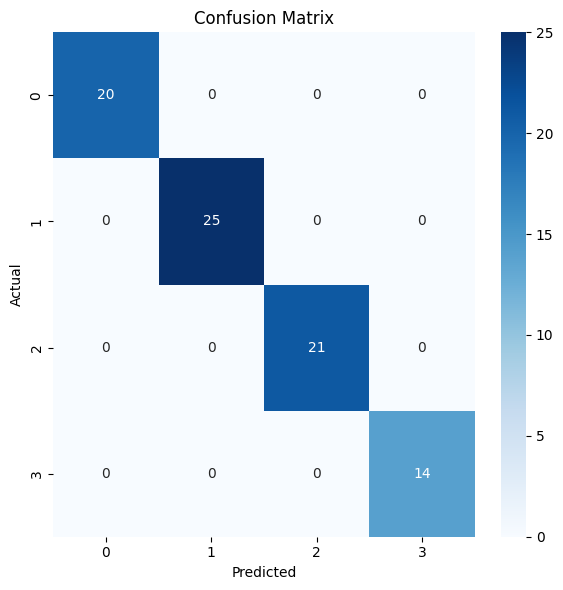

In [5]:
import torch
import time
import numpy as np
import pandas as pd
from transformers import BertTokenizer, BertForSequenceClassification
from torch.nn.functional import softmax
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

print("\n📦 Running inference.py...")

# Device setup
device = torch.device("cpu")
print("⚠️ Using CPU for inference (MPS and CUDA not available)")

# Paths
model_path = "bert_request_classifier"  # Corrected path to trained model
test_path = "data/dataset_final_test.csv"

# Load trained model and tokenizer
print("\n🔄 Loading trained model from:", model_path)
model = BertForSequenceClassification.from_pretrained(model_path)
tokenizer = BertTokenizer.from_pretrained(model_path)
model.to(device)
model.eval()
print("✅ Model loaded successfully!")

# Load test dataset
df_test = pd.read_csv(test_path)

assert (
    "Request" in df_test.columns and "Label" in df_test.columns
), "❌ Test dataset must contain 'Request' and 'Label' columns"

test_texts = df_test["Request"].tolist()
test_labels = list(map(int, df_test["Label"].tolist()))  # Ensure ints

if not test_texts:
    raise ValueError("❌ No test samples found! Check the test dataset.")

# Inference loop
inference_times = []
predictions = []

print("\n🚀 Running inference on the test set...")

for text in test_texts:
    inputs = tokenizer(text, padding=True, truncation=True, return_tensors="pt").to(
        device
    )

    start_time = time.time()
    with torch.no_grad():
        outputs = model(**inputs)
        probs = softmax(outputs.logits, dim=1)
        prediction = torch.argmax(probs, dim=1).item()
    end_time = time.time()

    predictions.append(prediction)
    inference_times.append(end_time - start_time)

# Metrics
avg_inference_time = np.mean(inference_times)
accuracy = accuracy_score(test_labels, predictions)
report = classification_report(test_labels, predictions, digits=4)
conf_matrix = confusion_matrix(test_labels, predictions)

# Print results
print(f"\n🕒 Avg inference time per sentence: {avg_inference_time:.6f} sec")
print(f"✅ Accuracy: {accuracy:.4f}")
print("\n📊 Classification Report:\n", report)

# Plot confusion matrix
plt.figure(figsize=(6, 6))
sns.heatmap(
    conf_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=range(model.config.num_labels),
    yticklabels=range(model.config.num_labels),
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()